# 04 · Global explanations: what has the model learned overall?

**Question:** which words drive the recommender *across all titles*, do different global
methods agree, and can the whole model be summarised by a small decision tree without
losing fidelity?

| method | what it measures |
|---|---|
| **Coefficients** | the model's own weights per venue (exact for a linear model) |
| **Permutation importance** | how much test accuracy drops when a word's TF-IDF column is shuffled (Breiman, 2001) |
| **Global surrogate tree** | a shallow decision tree trained to imitate the model (Craven & Shavlik, 1996), judged by its *fidelity* |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

from tcner_xai import plotting
from tcner_xai.config import CLASSES, RESULTS_DIR, SEED
from tcner_xai.model import load_bundle

plotting.set_style()
B = load_bundle()
model = B.model
names = model.feature_names_
W = model.clf.coef_
y_test = B.y_test

train=21,497 test=3,373 features=5,000 test accuracy=0.8615


## 1. Coefficients per venue

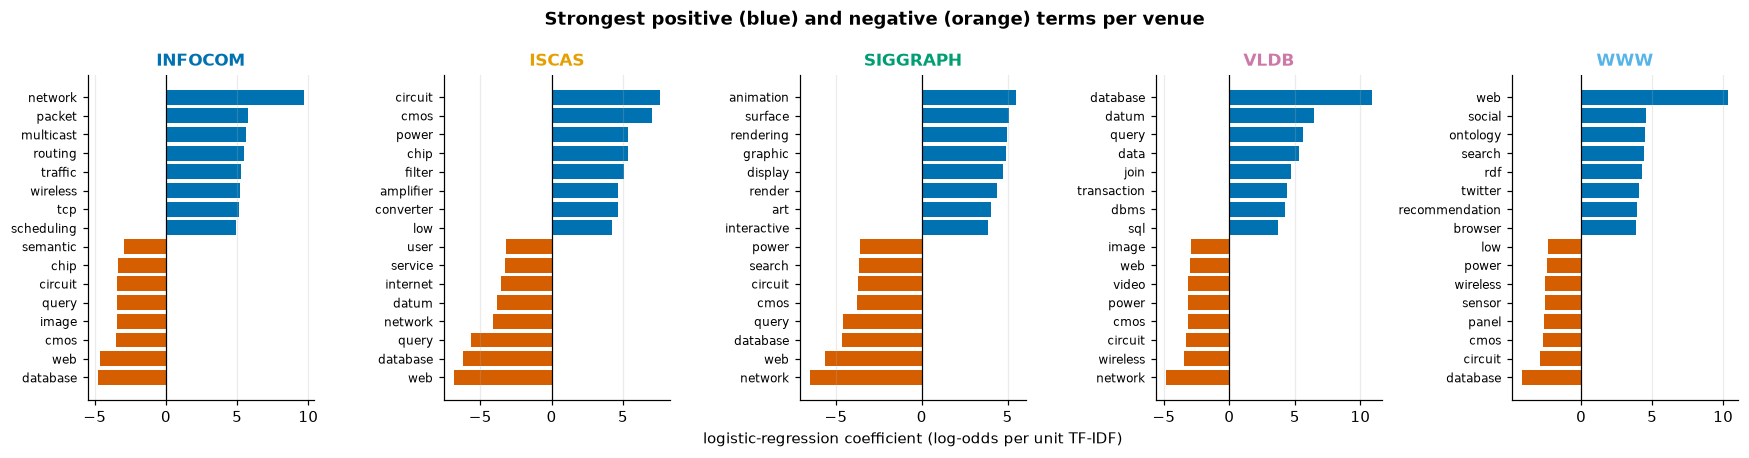

In [2]:
TOP = 8
fig, axes = plt.subplots(1, 5, figsize=(16, 4.2))
coef_rows = []
for ax, (k, venue) in zip(axes, enumerate(model.classes_)):
    order = np.argsort(W[k])
    idx = np.r_[order[:TOP], order[-TOP:]]
    ax.barh([names[j] for j in idx], W[k, idx],
            color=[plotting.NEG] * TOP + [plotting.POS] * TOP)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(venue, color=plotting.VENUE_COLORS[venue])
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)
    for j in idx:
        coef_rows.append({"venue": venue, "term": names[j], "coefficient": W[k, j]})
axes[2].set_xlabel("logistic-regression coefficient (log-odds per unit TF-IDF)")
fig.suptitle("Strongest positive (blue) and negative (orange) terms per venue", fontweight="bold")
fig.tight_layout()
plotting.save(fig, "04_coefficients")
plt.show()
pd.DataFrame(coef_rows).to_csv(RESULTS_DIR / "global_coefficients.csv", index=False)

## 2. Permutation importance (with uncertainty)

For a linear model the effect of shuffling one column can be computed exactly and
cheaply: the decision scores change by (x_perm − x) · wⱼ. This lets us use **all
5,000 features, all 3,373 test titles and 30 repeats** (the original used 500 samples
and 10 repeats). Columns that are all-zero on the test set have importance exactly 0 and
are skipped. We validate the fast implementation against a direct re-prediction.

In [3]:
X = B.X_test.tocsc()
base_scores = model.clf.decision_function(B.X_test)
y_idx = np.array([model.class_index(c) for c in y_test])
base_acc = (base_scores.argmax(1) == y_idx).mean()
active = np.flatnonzero(np.diff(X.indptr) > 0)
N_REPEATS = 30
rng = np.random.default_rng(SEED)


def permuted_accuracy(j, perm, col=None):
    col = X[:, j].toarray().ravel() if col is None else col
    delta = col[perm] - col
    scores = base_scores + np.outer(delta, W[:, j])
    return (scores.argmax(1) == y_idx).mean()


# validation against an explicit re-prediction for three features
for j in active[:3]:
    perm = rng.permutation(X.shape[0])
    Xp = B.X_test.tolil(copy=True)
    Xp[:, j] = X[:, j].toarray()[perm]
    direct = (model.clf.predict(Xp.tocsr()) == y_test).mean()
    assert np.isclose(direct, permuted_accuracy(j, perm)), "fast permutation importance is wrong"
print("fast permutation importance matches direct re-prediction ✓")

imp = np.zeros((len(names), N_REPEATS))
for j in active:
    col = X[:, j].toarray().ravel()
    imp[j] = [base_acc - permuted_accuracy(j, rng.permutation(X.shape[0]), col) for _ in range(N_REPEATS)]
pi = pd.DataFrame({"term": names, "importance": imp.mean(1), "std": imp.std(1),
                   "test_docs": np.diff(X.indptr), "venue (largest coef)": model.classes_[W.argmax(0)]})
pi = pi.sort_values("importance", ascending=False).reset_index(drop=True)
pi.head(200).to_csv(RESULTS_DIR / "global_permutation_importance.csv", index=False)
display(pi.head(20))

fast permutation importance matches direct re-prediction ✓


,term,importance,std,test_docs,venue (largest coef)
0,web,0.012590,0.001098,71,WWW
1,network,0.010090,0.001951,422,INFOCOM
2,circuit,0.007955,0.001672,229,ISCAS
3,filter,0.006414,0.001711,346,ISCAS
4,query,0.005811,0.000764,49,VLDB
5,database,0.005722,0.000747,26,VLDB
6,cloud,0.005406,0.000581,66,INFOCOM
7,neural,0.005020,0.001239,147,ISCAS
8,social,0.004744,0.000959,96,WWW
9,signal,0.003992,0.001040,109,ISCAS


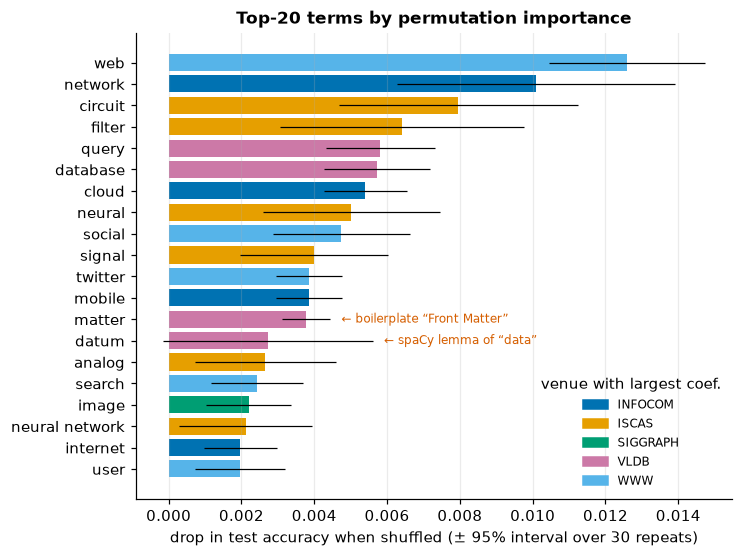

In [4]:
top = pi.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top["term"], top["importance"], xerr=1.96 * top["std"],
        color=[plotting.VENUE_COLORS[v] for v in top["venue (largest coef)"]], error_kw=dict(lw=0.8))
ax.set_xlabel("drop in test accuracy when shuffled (± 95% interval over 30 repeats)")
ax.set_title("Top-20 terms by permutation importance")
handles = [plt.Rectangle((0, 0), 1, 1, color=plotting.VENUE_COLORS[c]) for c in CLASSES]
ax.legend(handles, CLASSES, title="venue with largest coef.", fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
ARTEFACTS = {"matter": "← boilerplate “Front Matter”", "datum": "← spaCy lemma of “data”"}
for y, (term, val, sd) in enumerate(zip(top["term"], top["importance"], top["std"])):
    if term in ARTEFACTS:
        ax.text(val + 1.96 * sd + 0.0003, y, ARTEFACTS[term], va="center", fontsize=8, color="#D55E00")
plotting.save(fig, "04_permutation_importance")
plt.show()

## 3. Do global methods agree?

We compare three global rankings over the vocabulary: permutation importance, the
largest absolute coefficient, and the mean absolute contribution |wⱼ·xⱼ| over the test
set (a SHAP-style global summary). Coefficients ignore how often a word occurs;
permutation importance and mean contribution both account for frequency.

In [5]:
pred_idx = base_scores.argmax(1)
# mean |w_{pred, j} * x_j| using each title's predicted venue
Xc = B.X_test.tocoo()
mean_contrib = np.zeros(len(names))
np.add.at(mean_contrib, Xc.col, np.abs(Xc.data * W[pred_idx[Xc.row], Xc.col]))
mean_contrib /= B.X_test.shape[0]
glob = pd.DataFrame({"permutation": imp.mean(1), "max |coef|": np.abs(W).max(0), "mean |w·x|": mean_contrib},
                    index=names)
rank_corr = glob.corr(method="spearman").round(3)
top20 = {c: set(glob[c].nlargest(20).index) for c in glob}
overlap = pd.DataFrame({a: {b: len(top20[a] & top20[b]) / 20 for b in glob} for a in glob})
display(rank_corr)
display(overlap)
rank_corr.to_csv(RESULTS_DIR / "global_rank_correlation.csv")
overlap.to_csv(RESULTS_DIR / "global_top20_overlap.csv")
print("Top-10 by |coef| that are NOT in permutation top-50:",
      sorted(set(glob["max |coef|"].nlargest(10).index) - set(glob["permutation"].nlargest(50).index)))

,permutation,max |coef|,mean |w·x|
permutation,1.000,0.237,0.248
max |coef|,0.237,1.000,0.521
mean |w·x|,0.248,0.521,1.000


,permutation,max |coef|,mean |w·x|
permutation,1.00,0.35,0.55
max |coef|,0.35,1.00,0.40
mean |w·x|,0.55,0.40,1.00


Top-10 by |coef| that are NOT in permutation top-50: ['packet', 'routing']


## 4. Global surrogate: how much of the model can a small tree explain?

A surrogate is only useful if it imitates the model. We train trees of increasing depth
on the model's *predictions* for the training titles and measure **fidelity** = agreement
with the model on the *test* titles (not seen by either). The original project reported a
depth-3/4 tree without its fidelity.

,max_depth,leaves,fidelity (test),accuracy (test)
0,1,2,0.6184,0.5980
1,2,4,0.6451,0.6190
2,3,8,0.6890,0.6635
3,4,15,0.6994,0.6715
4,5,26,0.7166,0.6751
5,6,38,0.7178,0.6760
6,8,66,0.7181,0.6757
7,10,97,0.7228,0.6774
8,15,192,0.7444,0.6994
9,20,300,0.7572,0.7080


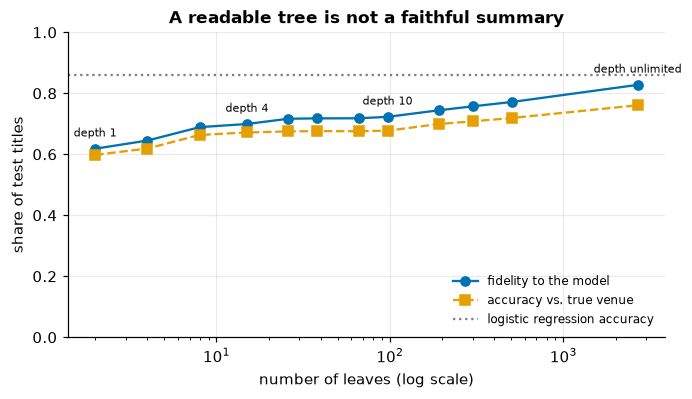

In [6]:
train_pred = model.clf.predict(B.X_train)
test_pred = model.clf.predict(B.X_test)
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(B.X_train, train_pred)
    p = tree.predict(B.X_test)
    rows.append({"max_depth": depth if depth else "unlimited", "leaves": tree.get_n_leaves(),
                 "fidelity (test)": (p == test_pred).mean(), "accuracy (test)": (p == y_test).mean()})
fid = pd.DataFrame(rows).round(4)
fid.to_csv(RESULTS_DIR / "surrogate_fidelity.csv", index=False)
display(fid)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(fid["leaves"], fid["fidelity (test)"], "o-", label="fidelity to the model", color="#0072B2")
ax.plot(fid["leaves"], fid["accuracy (test)"], "s--", label="accuracy vs. true venue", color="#E69F00")
ax.axhline((test_pred == y_test).mean(), color="gray", ls=":", label="logistic regression accuracy")
ax.set_xscale("log")
ax.set_xlabel("number of leaves (log scale)")
ax.set_ylabel("share of test titles")
ax.set_ylim(0, 1)
ax.set_title("A readable tree is not a faithful summary")
for _, r in fid.iterrows():
    if str(r["max_depth"]) in ("1", "4", "10", "unlimited"):
        ax.annotate(f"depth {r['max_depth']}", (r["leaves"], r["fidelity (test)"]), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=7.5)
ax.legend(fontsize=8, loc="lower right")
plotting.save(fig, "04_surrogate_fidelity")
plt.show()

depth-4 surrogate: fidelity 0.699; per predicted venue:
INFOCOM     0.408
ISCAS       0.977
SIGGRAPH    0.000
VLDB        0.222
WWW         0.262


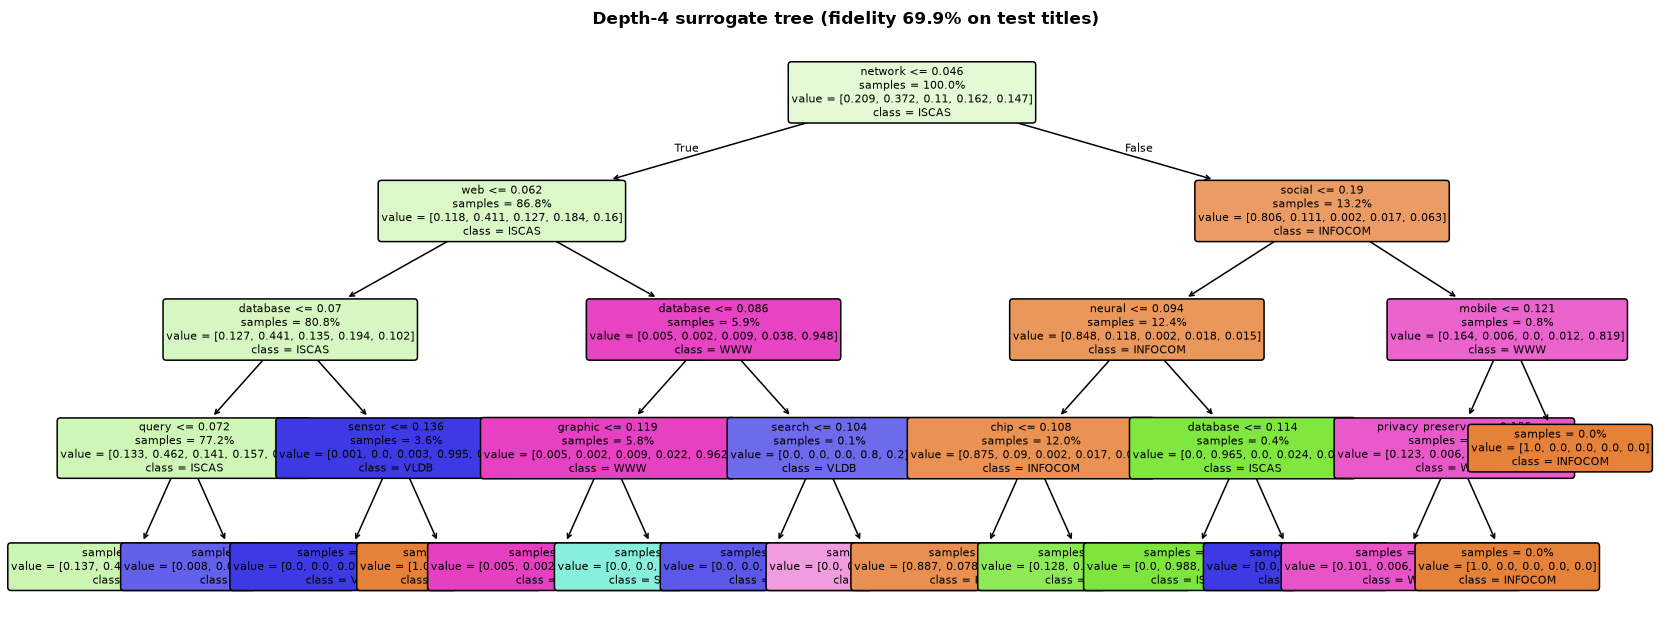

|--- network <= 0.05
|   |--- web <= 0.06
|   |   |--- database <= 0.07
|   |   |   |--- query <= 0.07
|   |   |   |   |--- class: ISCAS
|   |   |   |--- query >  0.07
|   |   |   |   |--- class: VLDB
|   |   |--- database >  0.07
|   |   |   |--- sensor <= 0.14
|   |   |   |   |--- class: VLDB
|   |   |   |--- sensor >  0.14
|   |   |   |   |--- class: INFOCOM
|   |--- web >  0.06
|   |   |--- database <= 0.09
|   |   |   |--- graphic <= 0.12
|   |   |   |   |--- class: WWW
|   |   |   |--- graphic >  0.12
|   |   |   |   |--- class: SIGGRAPH
|   |   |--- database >  0.09
|   |   |   |--- search <= 0.10
|   |   |   |   |--- class: VLDB
|   |   |   |--- search >  0.10
|   |   |   |   |--- class: WWW
|--- network >  0.05
|   |--- social <= 0.19
|   |   |--- neural <= 0.09
|   |   |   |--- chip <= 0.11
|   |   |   |   |--- class: INFOCOM
|   |   |   |--- chip >  0.11
|   |   |   |   |--- class: ISCAS
|   |   |--- neural >  0.09
|   |   |   |--- database <= 0.11
|   |   |   |   |--- class

In [7]:
tree4 = DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(B.X_train, train_pred)
fid4 = (tree4.predict(B.X_test) == test_pred).mean()
per_class = pd.Series({c: (tree4.predict(B.X_test)[test_pred == c] == c).mean() for c in CLASSES})
print(f"depth-4 surrogate: fidelity {fid4:.3f}; per predicted venue:\n{per_class.round(3).to_string()}")
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(tree4, feature_names=list(names), class_names=list(model.classes_), filled=True, rounded=True,
          fontsize=7, impurity=False, proportion=True, ax=ax)
ax.set_title(f"Depth-4 surrogate tree (fidelity {fid4:.1%} on test titles)")
plotting.save(fig, "04_surrogate_tree")
plt.show()
print(export_text(tree4, feature_names=list(names), max_depth=4))

## Take-aways

* Coefficients are the exact global explanation of this model and are coherent with
  domain knowledge (networking terms → INFOCOM, circuit terms → ISCAS, …).
* Permutation importance surfaces two **artefacts** among the 15 most important terms:
  `matter` (only from the boilerplate title *Front Matter*) and `datum` (spaCy lemmatises
  *data* → *datum*). Explanations doubled as a data-debugging tool here.
* The three global rankings **disagree** (Spearman 0.24–0.52; top-20 overlap 35–55%):
  words with large coefficients but few occurrences (e.g. `packet`, `routing`) barely
  affect accuracy. “Most important word” is not a single well-defined quantity.
* The depth-4 surrogate tree that the original report presented as a reasonable
  approximation reproduces the model on only **≈ 70%** of test titles and recovers
  **none** of its SIGGRAPH predictions; even an unlimited tree stays below 83%. A
  readable tree is not a faithful summary of a 5,000-feature linear model.